# Zillow traffic: web + app signals, backtest, last 2 months

**Questions:** how is overall Zillow traffic tracking in Aug–Oct 2026, and which alt-data signal is
worth trusting for reported traffic?

**Benchmarks (Visible Alpha, audited pull, `data/va_benchmarks.csv`):** reported quarterly
*Visits* and *Average monthly unique users* (MUU). Both cover all Zillow Group brands, web + app.

**Signals:**
- SimilarWeb `SIMILARWEB.COMMON.VISITS_V2`, metric `all_traffic_visits` (desktop + mobile web), daily from 2021-10-25.
  zillow.com is available for `US`. trulia.com and streeteasy.com only have daily `WW` (their `US` rows are a
  6-week 2026 stub), so the group-web signal uses WW for those two (they are almost all US traffic).
  hotpads.com is not tracked.
- SensorTower `SENSORTOWER.COMMON.CORE`, US, iOS + Android phone. `TICKER` is NULL for Zillow apps, so we filter on
  product name. `SESSIONS` stops at 2026-10-03 and `DAU` at 2026-10-09.

**Caveats that shape everything below:**
- SimilarWeb restates history in place and keeps no vintages, so the backtest uses today's vintage of the
  signal. It is a mildly optimistic, in-sample-of-vintage test.
- Do not sum SimilarWeb across countries: `US-IL` is a subset of `US`, and `WW` = `US` + `ROW`.
- `MAU` in SensorTower is a monthly value repeated on each day. Take one value per month and device.
- The 2026-08-18 SimilarWeb incident affected marketing-channel metrics only (backfilled to 2023-08-15),
  not `all_traffic_visits`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from common import q, va, backtest_stats, OUT
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Reference palette (dataviz skill, validated): fixed categorical order, never cycled
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, SURF = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10, "legend.frameon": False})
def save(fig, name):
    fig.savefig(OUT / f"traffic_{name}.png", dpi=150, bbox_inches="tight")

## 1. Pull the signals

In [2]:
DOMAINS = ("zillow.com", "trulia.com", "streeteasy.com", "realtor.com", "redfin.com", "homes.com", "compass.com", "apartments.com")
sw = q(f"""select domain, country, date, value from similarweb.common.visits_v2
           where metric = 'all_traffic_visits' and domain in {DOMAINS}""")
sw["date"] = pd.to_datetime(sw["date"])
def web(domain, country):
    return sw[(sw.domain == domain) & (sw.country == country)].set_index("date")["value"].sort_index()

GROUP_APPS = ["Zillow Real Estate & Rentals", "Trulia Real Estate & Rentals", "Zillow Rentals",
              "Trulia Rentals", "HotPads - Apartment Rentals", "StreetEasy NYC Rentals & Sales"]
PEER_APPS = ["Redfin: Buy, Sell & Rent Homes", "Realtor.com Real Estate & Rent", "Homes.com Real Estate & Rent",
             "Apartments.com Rental Finder", "Airbnb", "Amazon Shopping", "Instagram", "Walmart: Shopping & Savings", "Reddit"]
names = ",".join("'" + a + "'" for a in GROUP_APPS + PEER_APPS)
st = q(f"""select unified_product_name app, device_code dev, date, dau, mau, sessions, downloads
           from sensortower.common.core
           where country_code = 'US' and date >= '2020-01-01' and unified_product_name in ({names})""")
st["date"] = pd.to_datetime(st["date"])
print("SimilarWeb through", sw.date.max().date(), "| SensorTower DAU through", st.dropna(subset=["dau"]).date.max().date(),
      "| sessions through", st.dropna(subset=["sessions"]).date.max().date())

SimilarWeb through 2026-10-10 | SensorTower DAU through 2026-10-09 | sessions through 2026-10-03


In [3]:
zus = web("zillow.com", "US")
grp_web = zus.add(web("trulia.com", "WW"), fill_value=0).add(web("streeteasy.com", "WW"), fill_value=0)
app = st[st.app.isin(GROUP_APPS)]
app_sessions = app.groupby("date").sessions.sum(min_count=1)
main_dau = st[st.app == "Zillow Real Estate & Rentals"].groupby("date").dau.sum(min_count=1)   # iOS + Android
mau_m = (app.assign(m=app.date.dt.to_period("M")).groupby(["m", "app", "dev"]).mau.first()
         .groupby("m").sum())   # one MAU per app/device/month, summed (overlap across apps is ignored)

def q_agg(s, how="sum", need=0.98):
    """Calendar-quarter aggregate, dropping quarters with < need share of days present."""
    d = s.dropna().to_frame("v"); d["q"] = d.index.to_period("Q")
    g = d.groupby("q").v.agg([how, "count"])
    days = pd.Series({p: (p.end_time.normalize() - p.start_time.normalize()).days + 1 for p in g.index})
    return g.loc[g["count"] >= need * days, how]

mq = mau_m.to_frame("v"); mq["q"] = mq.index.asfreq("Q")
mau_q = mq.groupby("q").v.agg(["mean", "count"]).query("count == 3")["mean"]

sig = pd.DataFrame({
    "a_zillow_web_us": q_agg(zus),
    "b_group_web": q_agg(grp_web),
    "app_sessions": q_agg(app_sessions),
    "app_mau": mau_q,
    "main_app_dau": q_agg(main_dau, "mean"),
})
sig["c_web_plus_app"] = sig.b_group_web + sig.app_sessions
sig = sig.loc["2022Q1":]
(sig / 1e6).round(1).tail(8)

,a_zillow_web_us,b_group_web,app_sessions,app_mau,main_app_dau,c_web_plus_app
q,,,,,,
2024Q4,902.1,996.1,1677.3,33.0,5.4,2673.3
2025Q1,983.7,1094.6,2066.8,34.5,6.1,3161.5
2025Q2,1030.7,1139.3,2350.8,37.0,6.8,3490.1
2025Q3,973.6,1073.5,2341.3,37.6,6.9,3414.8
2025Q4,840.8,919.7,1924.4,36.2,6.1,2844.1
2026Q1,931.2,1016.6,2174.8,35.3,6.5,3191.5
2026Q2,1042.9,1137.2,2334.3,34.7,6.5,3471.5
2026Q3,1023.6,1116.6,2014.6,31.8,5.7,3131.2


## 2. Benchmark and backtest

For each signal and benchmark (reported visits, reported MUU), three things:
- **YoY correlation** between the signal and the reported KPI (2023Q1+).
- **Ratio nowcast (out-of-sample):** estimate = signal × mean(reported / signal) over the *prior* 4 quarters.
- **YoY nowcast:** estimate = reported a year earlier × signal YoY.

`backtest_stats` gives MAPE, bias, consensus MAPE on the same quarters, and the **beat/miss hit rate**
(does estimate > consensus correctly call reported > consensus?).

In [4]:
V = va("visits").set_index("quarter"); U = va("avg_monthly_unique_users").set_index("quarter")

def nowcasts(signal, bench):
    d = pd.DataFrame({"s": signal}).join(bench[["reported", "consensus"]], how="inner").sort_index()
    d["est_ratio"] = d.s * (d.reported / d.s).shift(1).rolling(4, min_periods=4).mean()
    d["est_yoy"] = d.reported.shift(4) * d.s / d.s.shift(4)
    d["s_yoy"], d["r_yoy"] = d.s / d.s.shift(4) - 1, d.reported / d.reported.shift(4) - 1
    return d

rows = []
for bname, B in [("visits", V), ("muu", U)]:
    for c in sig.columns:
        d = nowcasts(sig[c], B)
        corr = d[["s_yoy", "r_yoy"]].dropna().corr().iloc[0, 1]
        for m in ["est_ratio", "est_yoy"]:
            s = backtest_stats(d.rename(columns={m: "estimate"}))
            rows.append({"benchmark": bname, "signal": c, "method": m.replace("est_", ""), "yoy_corr": corr, **s.to_dict()})
bt = pd.DataFrame(rows)
bt.to_csv(OUT / "traffic_backtest.csv", index=False)
bt.drop(columns=["n_cons"]).round(3).sort_values(["benchmark", "mape"])

,benchmark,signal,method,yoy_corr,n,mape,bias,cons_mape,beat_miss_hit_rate
23,muu,c_web_plus_app,yoy,0.567,14.0,0.029,-0.014,0.020,0.643
20,muu,main_app_dau,ratio,0.686,14.0,0.031,-0.003,0.020,0.714
18,muu,app_mau,ratio,0.480,14.0,0.033,0.004,0.020,0.714
19,muu,app_mau,yoy,0.480,14.0,0.033,0.006,0.020,0.714
22,muu,c_web_plus_app,ratio,0.567,14.0,0.033,-0.002,0.020,0.429
21,muu,main_app_dau,yoy,0.686,14.0,0.044,-0.006,0.020,0.571
16,muu,app_sessions,ratio,0.638,14.0,0.046,0.003,0.020,0.571
12,muu,a_zillow_web_us,ratio,-0.441,14.0,0.048,0.005,0.020,0.500
14,muu,b_group_web,ratio,-0.528,14.0,0.048,-0.009,0.020,0.357
17,muu,app_sessions,yoy,0.638,14.0,0.049,-0.007,0.020,0.643


**Reading the backtest (n = 14 quarters, 2023Q1–2026Q2):**
- **Visits:** web + app combined (`c_web_plus_app`, ratio method) is the only signal that beats consensus on
  error (≈4.7% MAPE vs 6.7%). It also called beat/miss correctly in 13 of 14 quarters.
  App sessions and app DAU called beat/miss well (≈86%) but had higher error.
- **MUU:** consensus is tight (≈2% MAPE) and no signal beats it on error. App DAU and app MAU have the
  best YoY correlation (≈0.5–0.7) and a ≈71% hit rate.
- **Web-only signals are poor:** their YoY correlation with reported traffic is roughly zero, or negative for MUU.
  Zillow's reported traffic now follows its apps more than its website, so web visits alone cannot be used.

**Chosen signal:** `c_web_plus_app` (Zillow Group web visits + Zillow Group app sessions), ratio method, for
visits. For MUU, app DAU/MAU is used directionally. With 14 quarters, treat all of these error estimates as wide.

In [5]:
# Per-quarter view of the chosen signal: YoY of web, app, and reported
d = nowcasts(sig.c_web_plus_app, V)
yy = lambda s: s.pct_change(4, fill_method=None)
view = pd.DataFrame({
    "web_yoy": yy(sig.b_group_web), "app_sessions_yoy": yy(sig.app_sessions),
    "app_dau_yoy": yy(sig.main_app_dau), "combined_yoy": yy(sig.c_web_plus_app),
    "reported_visits_yoy": yy(V.reported), "reported_muu_yoy": yy(U.reported),
    "est_visits_vs_cons": d.est_ratio / d.consensus - 1, "reported_vs_cons": d.reported / d.consensus - 1,
}).loc["2023Q1":"2026Q3"]
view.style.format("{:+.1%}")

,web_yoy,app_sessions_yoy,app_dau_yoy,combined_yoy,reported_visits_yoy,reported_muu_yoy,est_visits_vs_cons,reported_vs_cons
2023Q1,-2.7%,-4.3%,-2.1%,-3.8%,-14.8%,+2.8%,+1.1%,-10.0%
2023Q2,-2.5%,-3.4%,-3.1%,-3.1%,-17.5%,-0.9%,-3.7%,-14.8%
2023Q3,+2.7%,-2.5%,-3.7%,-0.7%,-14.5%,-2.5%,-5.5%,-12.6%
2023Q4,+6.2%,+0.2%,-2.9%,+2.2%,-8.8%,+0.5%,-7.8%,-10.0%
2024Q1,+6.0%,-0.6%,-0.3%,+1.7%,+3.5%,+0.0%,-12.8%,-9.4%
2024Q2,+4.7%,-7.0%,-4.6%,-3.0%,+4.3%,-0.4%,-9.0%,-4.0%
2024Q3,-0.2%,-8.5%,-6.0%,-5.6%,+3.1%,+1.3%,-9.0%,-3.9%
2024Q4,+1.5%,-7.2%,-3.2%,-4.2%,+3.5%,+2.5%,-7.5%,-4.0%
2025Q1,-1.1%,+1.4%,+1.3%,+0.5%,+1.6%,+4.6%,+2.2%,+0.7%
2025Q2,-6.0%,+11.4%,+9.0%,+5.1%,+3.8%,+5.2%,+3.7%,+1.6%


## 3. Q3-26 nowcast against consensus

In [6]:
Q = pd.Period("2026Q3")
def point(signal, B):
    s, r = signal.dropna(), B.reported.dropna()
    ratio = (r / s).dropna().iloc[-4:].mean()
    return {"ratio": s[Q] * ratio, "yoy": r[Q - 4] * s[Q] / s[Q - 4], "signal_yoy": s[Q] / s[Q - 4] - 1}
nc = []
for bname, B in [("visits", V), ("muu", U)]:
    for c in sig.columns:
        p = point(sig[c], B)
        nc.append({"benchmark": bname, "signal": c, "signal_yoy": p["signal_yoy"],
                   "est_ratio_m": p["ratio"] / 1e6, "est_yoy_m": p["yoy"] / 1e6,
                   "consensus_m": B.consensus[Q] / 1e6, "ratio_vs_cons": p["ratio"] / B.consensus[Q] - 1})
nc = pd.DataFrame(nc); nc.to_csv(OUT / "traffic_q3_nowcast.csv", index=False)
nc.style.format({"signal_yoy": "{:+.1%}", "est_ratio_m": "{:,.0f}", "est_yoy_m": "{:,.0f}",
                 "consensus_m": "{:,.0f}", "ratio_vs_cons": "{:+.1%}"})

,benchmark,signal,signal_yoy,est_ratio_m,est_yoy_m,consensus_m,ratio_vs_cons
0,visits,a_zillow_web_us,+5.1%,"2,555","2,677","2,582",-1.0%
1,visits,b_group_web,+4.0%,"2,546","2,648","2,582",-1.4%
2,visits,app_sessions,-14.0%,"2,171","2,191","2,582",-15.9%
3,visits,app_mau,-15.4%,"2,094","2,154","2,582",-18.9%
4,visits,main_app_dau,-16.7%,"2,090","2,120","2,582",-19.1%
5,visits,c_web_plus_app,-8.3%,"2,291","2,335","2,582",-11.3%
6,muu,a_zillow_web_us,+5.1%,252,263,247,+2.2%
7,muu,b_group_web,+4.0%,251,260,247,+1.8%
8,muu,app_sessions,-14.0%,214,215,247,-13.2%
9,muu,app_mau,-15.4%,206,211,247,-16.6%


In [7]:
best = nc.query("benchmark == 'visits' and signal == 'c_web_plus_app'").iloc[0]
mape = bt.query("benchmark == 'visits' and signal == 'c_web_plus_app' and method == 'ratio'").mape.iloc[0]
lo, hi = best.est_ratio_m * (1 - mape), best.est_ratio_m * (1 + mape)
print(f"Q3-26 visits nowcast (web+app, ratio): {best.est_ratio_m:,.0f}M  (±1 MAPE: {lo:,.0f}–{hi:,.0f}M)"
      f"  vs consensus {best.consensus_m:,.0f}M  -> {best.ratio_vs_cons:+.1%}")
web_only = nc.query("benchmark == 'visits' and signal == 'b_group_web'").iloc[0]
print(f"Web-only would say {web_only.est_ratio_m:,.0f}M ({web_only.ratio_vs_cons:+.1%}); the gap is all app-driven")
for s in ["main_app_dau", "app_mau", "c_web_plus_app", "b_group_web"]:
    r = nc.query("benchmark == 'muu' and signal == @s").iloc[0]
    print(f"MUU via {s:16s}: {r.est_ratio_m:,.0f}M ({r.ratio_vs_cons:+.1%} vs consensus {r.consensus_m:,.0f}M)")

Q3-26 visits nowcast (web+app, ratio): 2,291M  (±1 MAPE: 2,184–2,398M)  vs consensus 2,582M  -> -11.3%
Web-only would say 2,546M (-1.4%); the gap is all app-driven
MUU via main_app_dau    : 206M (-16.6% vs consensus 247M)
MUU via app_mau         : 206M (-16.6% vs consensus 247M)
MUU via c_web_plus_app  : 226M (-8.4% vs consensus 247M)
MUU via b_group_web     : 251M (+1.8% vs consensus 247M)


### Backtest in YoY terms, and how the signal is tracking by month

The ratio estimate is a level, so it is shown here as implied YoY against reported visits a year earlier.
Q3-26 is the live nowcast. Its whisker is ±1 backtest MAPE.

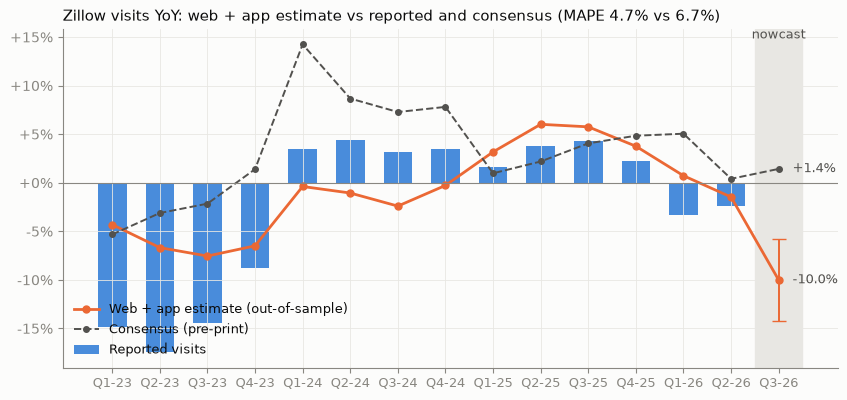

,Reported,Web + app estimate,Consensus
2023Q1,-14.8%,-4.3%,-5.3%
2023Q2,-17.5%,-6.7%,-3.1%
2023Q3,-14.5%,-7.5%,-2.2%
2023Q4,-8.8%,-6.5%,+1.4%
2024Q1,+3.5%,-0.4%,+14.2%
2024Q2,+4.3%,-1.1%,+8.7%
2024Q3,+3.1%,-2.4%,+7.3%
2024Q4,+3.5%,-0.3%,+7.8%
2025Q1,+1.6%,+3.2%,+1.0%
2025Q2,+3.8%,+6.0%,+2.2%


In [8]:
d = nowcasts(sig.c_web_plus_app, V)
ly = d.reported.shift(4)
yq = pd.DataFrame({"Reported": d.reported / ly - 1, "Web + app estimate": d.est_ratio / ly - 1,
                   "Consensus": d.consensus / ly - 1}).loc["2023Q1":"2026Q3"]
lab = [f"Q{p.quarter}-{str(p.year)[2:]}" for p in yq.index]
x = np.arange(len(yq)); xq = x[-1]

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x, yq.Reported, color=C[0], alpha=0.85, width=0.6, label="Reported visits")
ax.plot(x, yq["Web + app estimate"], color=C[1], marker="o", ms=5, label="Web + app estimate (out-of-sample)")
ax.plot(x, yq.Consensus, color=INK2, ls="--", marker="o", ms=4, lw=1.4, label="Consensus (pre-print)")
e = d.est_ratio[Q]
ax.errorbar(xq, e / ly[Q] - 1, yerr=[[e * mape / ly[Q]], [e * mape / ly[Q]]], color=C[1], capsize=5, lw=1.4)
ax.axvspan(xq - 0.5, xq + 0.5, color="#e8e7e3", zorder=0)
ax.text(xq, ax.get_ylim()[1], "nowcast", ha="center", va="top", fontsize=9, color=INK2)
for k in ["Web + app estimate", "Consensus"]:
    v = yq.loc[Q, k]
    ax.annotate(f"{v:+.1%}", (xq, v), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(x, lab, fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
cons_mape = bt.query("benchmark == 'visits' and signal == 'c_web_plus_app' and method == 'ratio'").cons_mape.iloc[0]
ax.set_title(f"Zillow visits YoY: web + app estimate vs reported and consensus (MAPE {mape:.1%} vs {cons_mape:.1%})",
             loc="left", fontsize=11)
ax.legend(loc="lower left", fontsize=9)
save(fig, "visits_backtest_yoy"); plt.show()
yq.style.format("{:+.1%}", na_rep="")

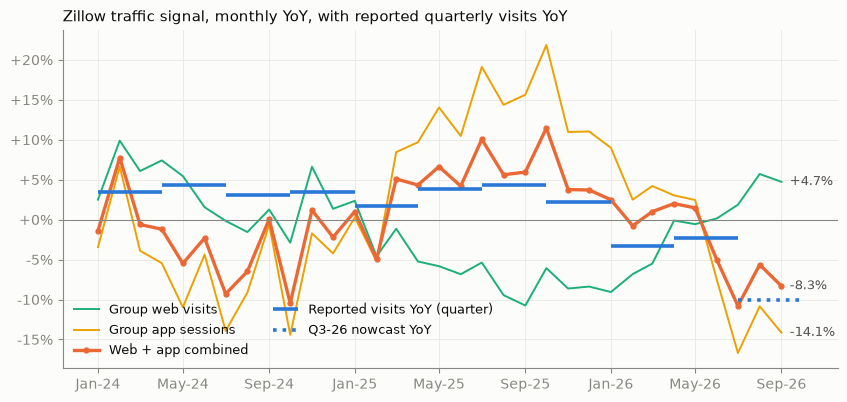

,web,app,combined
m,,,
2025-07,-5.4%,+19.1%,+10.0%
2025-08,-9.5%,+14.4%,+5.6%
2025-09,-10.7%,+15.6%,+5.9%
2025-10,-6.1%,+21.9%,+11.4%
2025-11,-8.6%,+11.0%,+3.8%
2025-12,-8.4%,+11.0%,+3.7%
2026-01,-9.1%,+9.0%,+2.5%
2026-02,-6.8%,+2.5%,-0.8%
2026-03,-5.5%,+4.2%,+1.0%


In [9]:
# Monthly YoY of the signal and its two parts (full months only; app sessions end 2026-10-03)
def m_agg(s, need=0.98):
    m = s.dropna().to_frame("v"); m["m"] = m.index.to_period("M")
    g = m.groupby("m").v.agg(["sum", "count"])
    return g.loc[g["count"] >= need * g.index.days_in_month, "sum"]
mon = pd.DataFrame({"web": m_agg(grp_web), "app": m_agg(app_sessions)}).dropna()
mon["combined"] = mon.web + mon.app
my = (mon / mon.shift(12) - 1).loc["2024-01":]
rep_q = yq.Reported.copy(); rep_q[Q] = yq.loc[Q, "Web + app estimate"]   # Q3-26: nowcast in place of reported

fig, ax = plt.subplots(figsize=(10, 4.4))
t = my.index.to_timestamp()
ax.plot(t, my.web, color=C[2], lw=1.4, label="Group web visits")
ax.plot(t, my.app, color=C[3], lw=1.4, label="Group app sessions")
ax.plot(t, my.combined, color=C[1], lw=2.4, marker="o", ms=3.5, label="Web + app combined")
for p, v in rep_q.loc["2024Q1":].items():
    a, b = p.start_time, p.end_time
    live = p == Q
    ax.hlines(v, a, b, color=C[0], lw=2.6, ls=":" if live else "-",
              label=("Reported visits YoY (quarter)" if p == pd.Period("2024Q1") else
                     "Q3-26 nowcast YoY" if live else None))
for c in ["web", "app", "combined"]:
    ax.annotate(f"{my[c].iloc[-1]:+.1%}", (t[-1], my[c].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_title("Zillow traffic signal, monthly YoY, with reported quarterly visits YoY", loc="left", fontsize=11)
ax.legend(loc="lower left", ncol=2, fontsize=9)
save(fig, "visits_monthly_yoy"); plt.show()
my.loc["2025-07":].style.format("{:+.1%}")

In [10]:
# Cross-check: expanding OLS of reported YoY on web YoY + app-sessions YoY (fit only on prior quarters, min 6)
def ols_nowcast(B):
    d = pd.DataFrame({"w": sig.b_group_web, "a": sig.app_sessions, "reported": B.reported, "consensus": B.consensus})
    y = d[["w", "a", "reported"]].pct_change(4, fill_method=None)
    est = {}
    for qq in y.index:
        tr = y.loc[:qq].iloc[:-1].dropna()
        if len(tr) < 6 or pd.isna(y.loc[qq, "w"]): continue
        X = np.c_[np.ones(len(tr)), tr.w, tr.a]
        b = np.linalg.lstsq(X, tr.reported, rcond=None)[0]
        est[qq] = d.reported.shift(4)[qq] * (1 + b @ [1, y.loc[qq, "w"], y.loc[qq, "a"]])
    d["estimate"] = pd.Series(est)
    return d
for bname, B in [("visits", V), ("muu", U)]:
    d = ols_nowcast(B)
    print(bname, backtest_stats(d).round(3).to_dict(), f"| Q3-26 est {d.estimate[Q]/1e6:,.0f}M vs cons {B.consensus[Q]/1e6:,.0f}M")

visits {'n': 8.0, 'mape': 0.094, 'bias': -0.092, 'cons_mape': 0.031, 'beat_miss_hit_rate': 0.625, 'n_cons': 8.0} | Q3-26 est 2,358M vs cons 2,582M
muu {'n': 8.0, 'mape': 0.028, 'bias': 0.001, 'cons_mape': 0.024, 'beat_miss_hit_rate': 0.5, 'n_cons': 8.0} | Q3-26 est 244M vs cons 247M


## 3b. Web/app weighting

The plain sum weights the app by its raw SensorTower session volume, about two-thirds. Nothing ties that to how
Zillow's reported visits split. Two ways to set the weight explicitly:
- **Level (ratio method):** signal = web + k × app sessions, with k chosen so the app is share *w* of the 2022 total.
  It is then scaled with the same trailing 4-quarter ratio. At *w* = the 2022 share this is exactly the plain sum.
- **YoY blend:** estimate = reported a year earlier × (1 + (1−w) × web YoY + w × app YoY).

Plus a fitted weight: *w* is re-estimated each quarter from prior quarters only (least squares on YoY, clipped to [0, 1],
minimum 6 quarters). The fit therefore starts in Q3-24.

In [11]:
webq, appq = sig.b_group_web, sig.app_sessions
b22 = sig.loc["2022Q1":"2022Q4"]
share_2022 = b22.app_sessions.sum() / (b22.b_group_web.sum() + b22.app_sessions.sum())
share_q3 = (appq / (webq + appq))[Q]
print(f"App share of the plain sum: {share_2022:.0%} in 2022, {share_q3:.0%} in Q3-26")
ly_r = V.reported.shift(4)
wy, ay, ry = (s.pct_change(4, fill_method=None) for s in (webq, appq, V.reported))

def est_level(w):
    k = w / (1 - w) * b22.b_group_web.sum() / b22.app_sessions.sum()
    return nowcasts(webq + k * appq, V).est_ratio
def est_blend(w):
    return ly_r * (1 + (1 - w) * wy + w * ay)
def fitted_w(min_q=6):
    d = pd.DataFrame({"r": ry, "w": wy, "a": ay}).dropna(subset=["w", "a"])
    out = {}
    for qq in d.index:
        tr = d.loc[:qq].iloc[:-1].dropna()
        if len(tr) < min_q: continue
        x, y = tr.a - tr.w, tr.r - tr.w
        out[qq] = float(np.clip((x * y).sum() / (x * x).sum(), 0, 1))
    return pd.Series(out)
wfit = fitted_w()

def stats(est, lo, hi="2026Q2"):
    d = pd.DataFrame({"estimate": est, "reported": V.reported, "consensus": V.consensus}).loc[lo:hi]
    return backtest_stats(d)

cands = {"plain sum (ratio)": nowcasts(sig.c_web_plus_app, V).est_ratio}
for w in [0.3, 0.4, 0.5, 0.6]:
    cands[f"{w:.0%} app (ratio)"] = est_level(w)
for w in [0.3, 0.4, 0.5, 0.6]:
    cands[f"{w:.0%} app (YoY blend)"] = est_blend(w)
cands["fitted weight, past only (YoY blend)"] = ly_r * (1 + (1 - wfit) * wy + wfit * ay)
cands["OLS with intercept, past only"] = ols_nowcast(V).estimate
cands["consensus"] = V.consensus

WINDOWS = [("23Q1+", "2023Q1"), ("24Q1+", "2024Q1"), ("24Q3+", "2024Q3")]
rows = []
for name, e in cands.items():
    r = {"signal": name}
    for lab, lo in WINDOWS:
        s = stats(e, lo)
        r[f"MAPE {lab}"] = s.mape
        r[f"n {lab}"] = s.n
        if name != "consensus":
            r[f"hit {lab}"] = s.beat_miss_hit_rate
    r["bias 24Q1+"] = stats(e, "2024Q1").bias
    r["Q3-26 YoY"] = e[Q] / ly_r[Q] - 1
    r["Q3-26 vs cons"] = e[Q] / V.consensus[Q] - 1
    rows.append(r)
wt = pd.DataFrame(rows).set_index("signal")
wt.to_csv(OUT / "traffic_weighting_backtest.csv")
pct = [c for c in wt.columns if not c.startswith("n ")]
wt.style.format({c: "{:.1%}" for c in pct} | {c: "{:.0f}" for c in wt.columns if c.startswith("n ")}, na_rep="")

App share of the plain sum: 66% in 2022, 64% in Q3-26


,MAPE 23Q1+,n 23Q1+,hit 23Q1+,MAPE 24Q1+,n 24Q1+,hit 24Q1+,MAPE 24Q3+,n 24Q3+,hit 24Q3+,bias 24Q1+,Q3-26 YoY,Q3-26 vs cons
signal,,,,,,,,,,,,
plain sum (ratio),4.7%,14,92.9%,2.9%,10,100.0%,2.6%,8,100.0%,-0.6%,-10.0%,-11.3%
30% app (ratio),4.7%,14,71.4%,2.6%,10,70.0%,2.6%,8,62.5%,-1.6%,-4.6%,-6.0%
40% app (ratio),4.4%,14,78.6%,2.3%,10,80.0%,2.2%,8,75.0%,-1.4%,-6.2%,-7.5%
50% app (ratio),4.3%,14,85.7%,2.2%,10,90.0%,1.8%,8,87.5%,-1.1%,-7.6%,-8.9%
60% app (ratio),4.4%,14,92.9%,2.5%,10,100.0%,2.1%,8,100.0%,-0.8%,-9.1%,-10.4%
30% app (YoY blend),6.8%,14,50.0%,3.0%,10,70.0%,3.4%,8,62.5%,-2.5%,-1.4%,-2.8%
40% app (YoY blend),6.4%,14,50.0%,2.7%,10,70.0%,2.9%,8,62.5%,-2.1%,-3.2%,-4.5%
50% app (YoY blend),6.4%,14,57.1%,2.8%,10,80.0%,2.7%,8,75.0%,-1.7%,-5.0%,-6.3%
60% app (YoY blend),6.8%,14,57.1%,3.6%,10,80.0%,3.5%,8,75.0%,-1.2%,-6.8%,-8.1%


In [12]:
# Weight implied by each reported quarter: reported YoY = (1-w) x web YoY + w x app YoY, solved for w.
# Only shown where web and app YoY differ by > 5pp (otherwise the solve is unstable).
imp = pd.DataFrame({"web YoY": wy, "app YoY": ay, "reported YoY": ry}).loc["2023Q1":"2026Q2"]
gap = imp["app YoY"] - imp["web YoY"]
imp["implied app weight"] = ((imp["reported YoY"] - imp["web YoY"]) / gap).where(gap.abs() > 0.05)
imp["fitted w (past only)"] = wfit
imp.style.format({"web YoY": "{:+.1%}", "app YoY": "{:+.1%}", "reported YoY": "{:+.1%}",
                  "implied app weight": "{:.2f}", "fitted w (past only)": "{:.2f}"}, na_rep="")

,web YoY,app YoY,reported YoY,implied app weight,fitted w (past only)
2023Q1,-2.7%,-4.3%,-14.8%,,
2023Q2,-2.5%,-3.4%,-17.5%,,
2023Q3,+2.7%,-2.5%,-14.5%,3.32,
2023Q4,+6.2%,+0.2%,-8.8%,2.51,
2024Q1,+6.0%,-0.6%,+3.5%,0.38,
2024Q2,+4.7%,-7.0%,+4.3%,0.03,
2024Q3,-0.2%,-8.5%,+3.1%,-0.40,0.94
2024Q4,+1.5%,-7.2%,+3.5%,-0.23,0.65
2025Q1,-1.1%,+1.4%,+1.6%,,0.48
2025Q2,-6.0%,+11.4%,+3.8%,0.56,0.49


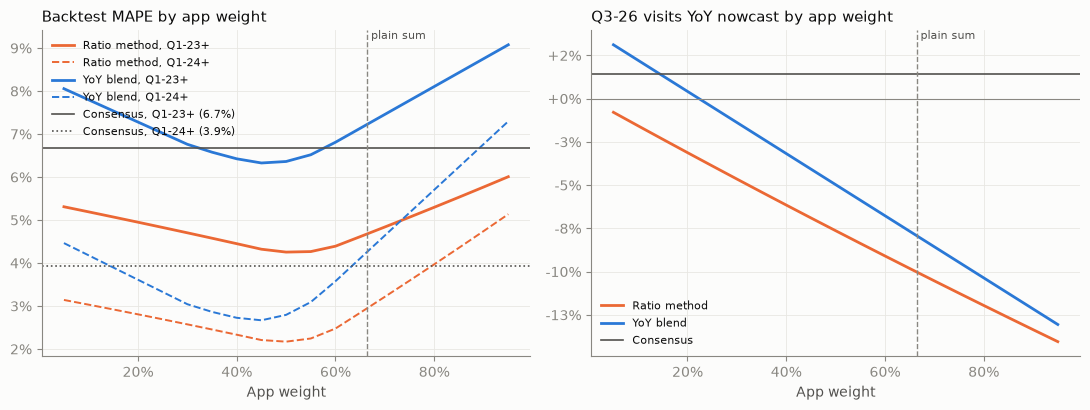

,ratio,blend,ratio_24,blend_24,q3_ratio,q3_blend
w,,,,,,
0.050000,5.3%,8.1%,3.1%,4.5%,-0.8%,3.1%
0.100000,5.2%,7.8%,3.0%,4.2%,-1.6%,2.2%
0.150000,5.1%,7.5%,2.9%,3.9%,-2.3%,1.3%
0.200000,4.9%,7.3%,2.8%,3.6%,-3.1%,0.4%
0.250000,4.8%,7.0%,2.7%,3.3%,-3.9%,-0.5%
0.300000,4.7%,6.8%,2.6%,3.0%,-4.6%,-1.4%
0.350000,4.6%,6.6%,2.5%,2.9%,-5.4%,-2.3%
0.400000,4.4%,6.4%,2.3%,2.7%,-6.2%,-3.2%
0.450000,4.3%,6.3%,2.2%,2.7%,-6.9%,-4.1%


In [13]:
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
sw_ = pd.DataFrame([{"w": w,
    "ratio": stats(est_level(w), "2023Q1").mape, "blend": stats(est_blend(w), "2023Q1").mape,
    "ratio_24": stats(est_level(w), "2024Q1").mape, "blend_24": stats(est_blend(w), "2024Q1").mape,
    "q3_ratio": est_level(w)[Q] / ly_r[Q] - 1, "q3_blend": est_blend(w)[Q] / ly_r[Q] - 1} for w in grid]).set_index("w")
cm_all, cm_24 = stats(V.consensus, "2023Q1").mape, stats(V.consensus, "2024Q1").mape

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(sw_.index, sw_.ratio, color=C[1], label="Ratio method, Q1-23+")
a1.plot(sw_.index, sw_.ratio_24, color=C[1], ls="--", lw=1.4, label="Ratio method, Q1-24+")
a1.plot(sw_.index, sw_.blend, color=C[0], label="YoY blend, Q1-23+")
a1.plot(sw_.index, sw_.blend_24, color=C[0], ls="--", lw=1.4, label="YoY blend, Q1-24+")
a1.axhline(cm_all, color=INK2, lw=1.2, label=f"Consensus, Q1-23+ ({cm_all:.1%})")
a1.axhline(cm_24, color=INK2, lw=1.2, ls=":", label=f"Consensus, Q1-24+ ({cm_24:.1%})")
a1.set_title("Backtest MAPE by app weight", loc="left", fontsize=11)
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a1.legend(fontsize=8, loc="upper left")
a2.plot(sw_.index, sw_.q3_ratio, color=C[1], label="Ratio method")
a2.plot(sw_.index, sw_.q3_blend, color=C[0], label="YoY blend")
a2.axhline(V.consensus[Q] / ly_r[Q] - 1, color=INK2, lw=1.2, label="Consensus")
a2.axhline(0, color=MUTED, lw=0.8)
a2.set_title("Q3-26 visits YoY nowcast by app weight", loc="left", fontsize=11)
a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
a2.legend(fontsize=8, loc="lower left")
for a in (a1, a2):
    a.axvline(share_2022, color=MUTED, lw=1, ls="--")
    a.text(share_2022, a.get_ylim()[1], " plain sum", fontsize=8, color=INK2, va="top")
    a.set_xlabel("App weight")
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); save(fig, "weight_sweep"); plt.show()
sw_.style.format("{:.1%}")

**Reading the weighting test (as of 2026-10-12):**
- **About 50% app is the best weight, but the gain is modest.** With the ratio method, MAPE falls from 4.7% to 4.3% (Q1-23+),
  2.9% to 2.2% (Q1-24+) and 2.6% to 1.8% (Q3-24+). The beat/miss hit rate drops slightly (9 of 10 vs 10 of 10 since Q1-24).
  The weight fitted on past quarters only settles at about 0.50 from Q2-25 on.
- **Reported visits imply an app weight of about 0.45–0.55 through 2025**, but in Q3–Q4 2024 it was below zero:
  reported grew faster than *both* web and app. In 2023 reported fell 9–18% while both sources fell about 3%. No weighting explains
  those two periods. That is the unreconciled part.
- **The OLS cross-check with an intercept is the worst method (9.4% MAPE).** Do not lean on its ≈2.36B.
- **Consensus edge:** consensus MAPE is 6.7% over Q1-23+ but only 3.9% over Q1-24+ and 3.1% over Q3-24+.
  The plain sum's lead over consensus comes mostly from 2023–24.
- **Q3-26:** the ratio method at 50% app gives **−7.6% YoY (−8.9% vs consensus)**, the YoY blend at 50% gives −5.0% (−6.3%), and
  the fitted weight gives −4.7% (−6.0%). The ratio method is more bearish because H2-25 app strength lowered the trailing ratio, and that
  lower ratio now multiplies a falling signal. Every variant with an app weight above about 15% is below the consensus of +1.4% YoY.

## 4. Last 2 months: daily, 7-day and 28-day YoY

In [14]:
def yoy_roll(s, w):
    r = s.rolling(w).sum()
    return r / r.shift(364) - 1          # 364 days keeps the weekday mix aligned
daily = pd.DataFrame({"Zillow Group web": grp_web, "zillow.com (US)": zus,
                      "Zillow Group app sessions": app_sessions.loc[:"2026-10-03"],
                      "Zillow app DAU": main_dau.loc[:"2026-10-09"]})
roll28 = daily.apply(yoy_roll, w=28); roll7 = daily.apply(yoy_roll, w=7)

def month_yoy(s):
    m = s.dropna().to_frame("v"); m["m"] = m.index.to_period("M"); m["dom"] = m.index.day
    cur = m[m.m >= "2026-08"]
    out = {}
    for per, g in cur.groupby("m"):
        days = g.dom.max()                            # month-to-date for October
        ly = m[(m.m == per - 12) & (m.dom <= days)].v.sum()
        out[str(per) + (" (MTD)" if per == pd.Period("2026-10") else "")] = g.v.sum() / ly - 1
    return pd.Series(out)
monthly = daily.apply(month_yoy).T
monthly.style.format("{:+.1%}")

,2026-08,2026-09,2026-10 (MTD)
Zillow Group web,+5.7%,+4.7%,+3.4%
zillow.com (US),+6.7%,+5.9%,+4.1%
Zillow Group app sessions,-10.9%,-14.1%,-18.0%
Zillow app DAU,-16.0%,-17.5%,-24.4%


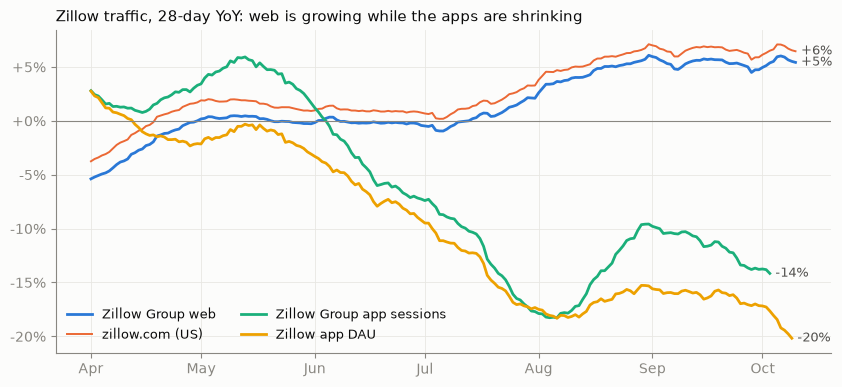

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
r = roll28.loc["2026-04-01":]
for i, c in enumerate(r.columns):
    ax.plot(r.index, r[c], color=C[i], label=c, lw=2 if i != 1 else 1.4)
    ax.annotate(f"{r[c].dropna().iloc[-1]:+.0%}", (r[c].dropna().index[-1], r[c].dropna().iloc[-1]),
                xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=9, va="center")
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Zillow traffic, 28-day YoY: web is growing while the apps are shrinking", loc="left", fontsize=11)
ax.legend(loc="lower left", ncol=2, fontsize=9)
save(fig, "28d_yoy"); plt.show()

In [16]:
# 2-year stack: the app's H2-25 comparison was +15-20%, so separate a tough comp from a real decline
def two_yr(s):
    m = s.dropna().resample("MS").mean()
    return (m / m.shift(24) - 1).loc["2026-01":"2026-09"]
pd.DataFrame({c: two_yr(daily[c]) for c in daily.columns}).T.style.format("{:+.1%}")

date,2026-01-01 00:00:00,2026-02-01 00:00:00,2026-03-01 00:00:00,2026-04-01 00:00:00,2026-05-01 00:00:00,2026-06-01 00:00:00,2026-07-01 00:00:00,2026-08-01 00:00:00,2026-09-01 00:00:00
Zillow Group web,-6.9%,-7.9%,-6.6%,-5.3%,-6.4%,-6.7%,-3.6%,-4.3%,-6.5%
zillow.com (US),-1.4%,-2.2%,-0.9%,+0.7%,-2.1%,-2.7%,-0.0%,-1.8%,-5.0%
Zillow Group app sessions,+9.3%,+0.6%,+13.0%,+13.0%,+16.8%,+2.1%,-0.8%,+2.0%,-0.7%
Zillow app DAU,+10.2%,+4.5%,+10.2%,+4.6%,+9.8%,-2.3%,-2.7%,-3.4%,-4.7%


## 5. Web vs app divergence: is the app decline real?

Checks:
1. iOS vs Android split.
2. The whole Zillow app family, not just the main app.
3. Downloads.
4. Whether the decline is a step change on one date, which would point to a SensorTower methodology change, or a gradual slide.
5. Peer real-estate apps and broad control apps over the same window. A SensorTower panel or model change
   would hit everyone.

In [17]:
mdau = st.assign(m=st.date.dt.to_period("M")).groupby(["app", "dev", "m"]).dau.mean().unstack("m")
dev_yoy = (mdau / mdau.shift(12, axis=1) - 1).loc[["Zillow Real Estate & Rentals", "Zillow Rentals", "Trulia Real Estate & Rentals"], "2026-01":]
dev_yoy.style.format("{:+.1%}")

In [18]:
fam = app.groupby("date")[["dau", "downloads"]].sum(min_count=1).loc[:"2026-10-09"]
fam_m = fam.resample("MS").mean()
pd.DataFrame({"family DAU YoY": fam_m.dau.pct_change(12, fill_method=None),
              "main-app DAU YoY": main_dau.loc[:"2026-10-09"].resample("MS").mean().pct_change(12, fill_method=None),
              "family downloads YoY": fam_m.downloads.pct_change(12, fill_method=None)}).loc["2026-01":].style.format("{:+.1%}")

,family DAU YoY,main-app DAU YoY,family downloads YoY
date,,,
2026-01-01 00:00:00,+8.0%,+11.9%,-16.9%
2026-02-01 00:00:00,+3.9%,+4.9%,-12.4%
2026-03-01 00:00:00,+3.7%,+4.5%,-8.2%
2026-04-01 00:00:00,-0.6%,-2.0%,-9.5%
2026-05-01 00:00:00,-2.3%,-2.5%,-18.1%
2026-06-01 00:00:00,-8.9%,-9.3%,-21.6%
2026-07-01 00:00:00,-16.6%,-16.7%,-28.2%
2026-08-01 00:00:00,-16.2%,-16.0%,-22.7%
2026-09-01 00:00:00,-17.5%,-17.5%,-20.9%


In [19]:
# Step test: weekly YoY of main-app DAU. A methodology break shows as one large week-on-week jump in YoY
w = main_dau.loc[:"2026-10-09"].resample("W").mean(); wy = w / w.shift(52) - 1
jumps = wy.diff().loc["2026-01":]
print("Largest week-on-week moves in main-app DAU YoY (2026):"); print(jumps.abs().nlargest(5).round(3))
peer = st[st.app.isin(PEER_APPS + ["Zillow Real Estate & Rentals"])].loc[lambda d: d.date <= "2026-10-09"]
pm = peer.assign(m=peer.date.dt.to_period("M")).groupby(["app", "m"]).dau.mean().unstack("app")
peer_yoy = (pm / pm.shift(12) - 1).loc["2026-01":].T
peer_yoy.style.format("{:+.1%}")

Largest week-on-week moves in main-app DAU YoY (2026):
date
2026-03-15    0.081
2026-01-25    0.074
2026-07-19    0.072
2026-01-11    0.066
2026-07-05    0.064
Name: dau, dtype: float64


m,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
app,,,,,,,,,,
Airbnb,+3.0%,+4.2%,-0.1%,-1.9%,-0.8%,-1.5%,-8.4%,-14.5%,-6.8%,-8.6%
Amazon Shopping,+2.3%,+2.2%,+1.5%,-0.2%,+0.8%,+2.0%,-8.0%,-2.7%,-1.9%,-3.0%
Apartments.com Rental Finder,-13.7%,-14.5%,-18.1%,+8.2%,-0.8%,+11.8%,+9.0%,+1.0%,+17.3%,+7.2%
Homes.com Real Estate & Rent,+30.2%,+3.3%,-10.2%,-10.2%,+1.1%,+25.3%,+3.7%,+17.0%,+47.6%,+36.0%
Instagram,+2.2%,+1.3%,-0.9%,-1.2%,-0.4%,-0.7%,-0.0%,+0.2%,+1.3%,+0.9%
Realtor.com Real Estate & Rent,+2.2%,+3.3%,-0.2%,-13.0%,-19.3%,-18.6%,-24.2%,-25.3%,-25.7%,-30.1%
Reddit,-4.1%,-6.7%,-9.8%,-10.1%,-9.7%,-9.6%,-7.0%,-4.7%,-4.6%,-6.7%
"Redfin: Buy, Sell & Rent Homes",-0.8%,+1.0%,-5.5%,-5.7%,-4.3%,-9.7%,-12.1%,-19.1%,-16.5%,-16.9%
Walmart: Shopping & Savings,+4.6%,+19.6%,+26.8%,+15.4%,+44.1%,+52.5%,+54.1%,+19.4%,+29.1%,+24.0%


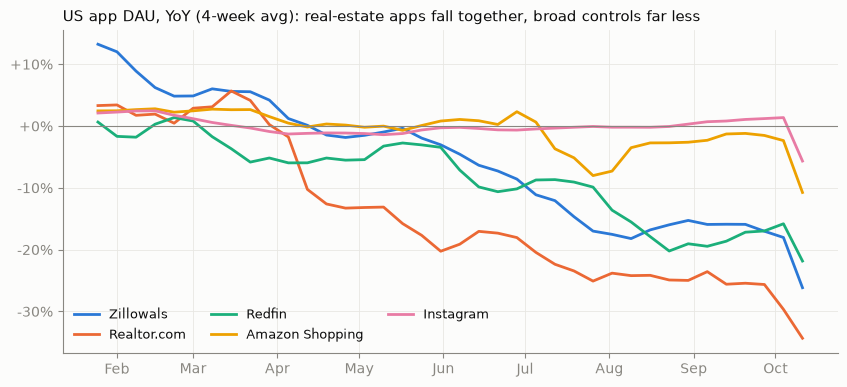

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.2))
show = {"Zillow Real Estate & Rentals": C[0], "Realtor.com Real Estate & Rent": C[1],
        "Redfin: Buy, Sell & Rent Homes": C[2], "Amazon Shopping": C[3], "Instagram": C[4]}
pmw = peer.set_index("date").groupby("app").dau.resample("W").sum().unstack("app")
pyw = (pmw / pmw.shift(52) - 1).loc["2026-01-01":]
for a, col in show.items():
    s = pyw[a].rolling(4).mean().dropna()
    ax.plot(s.index, s, color=col, label=a.split(":")[0].replace(" Real Estate & Rent", "").replace(" Real Estate & Rentals", ""))
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("US app DAU, YoY (4-week avg): real-estate apps fall together, broad controls far less", loc="left", fontsize=11)
ax.legend(loc="lower left", ncol=3, fontsize=9)
save(fig, "app_peers_yoy"); plt.show()

**Reading it:**
- **No step change.** Main-app DAU YoY slid gradually from about +15% (H2-25) to about −17% (Aug–Sep)
  and −24% in early October. iOS and Android move almost identically. The largest single-week move is small
  next to the cumulative slide.
- **It is not a Zillow-only effect.** Realtor.com's app is −25% to −30% and Redfin's is −17%.
  Broad controls are mixed but much milder: Instagram is flat, Amazon −2% to −3%, Reddit −5% to −7% and Airbnb −7% to −15%.
  Walmart is up, driven by its own product. Weakness concentrated in real-estate apps points to category demand
  (or a SensorTower model change specific to the category) rather than Zillow losing share in apps.
  Homes.com and Apartments.com (CoStar) are the exceptions, growing their apps.
- **Most of it is a tough comparison.** The Zillow app grew 15–20% YoY in H2-25. On a 2-year stack, main-app DAU is only about
  −3% to −5% in Jul–Sep. That is actually *better* than group web on a 2-year basis (−4% to −7%).
- **Web vs app:** the 1-year numbers diverge mostly because of the base. Web had a weak 2025 (it fell 6–8% YoY in Q2–Q4 25)
  and the apps had a strong one. The backtest says app signals tracked reported traffic better than web, so the
  app weakness should not be dismissed. Reported visits in H2-25 grew only about +2–4% while app sessions grew +15%, though, so
  app strength was not fully passed through to reported traffic then, and app weakness may not be now.

## 6. Share of US portal web visits

In [21]:
PORTALS = {"zillow.com": "US", "realtor.com": "US", "redfin.com": "US", "homes.com": "US", "compass.com": "US", "trulia.com": "WW"}
pw = pd.DataFrame({d: web(d, c) for d, c in PORTALS.items()}).loc["2023-08-01":"2026-09-30"].dropna()
pm_ = pw.resample("MS").sum(); share = pm_.div(pm_.sum(axis=1), axis=0)
tbl = pd.DataFrame({"Apr–Sep 2026": share.loc["2026-04":"2026-09"].mean(), "Apr–Sep 2025": share.loc["2025-04":"2025-09"].mean()})
tbl["change (pp)"] = (tbl.iloc[:, 0] - tbl.iloc[:, 1]) * 100
print("Trulia uses WW (no daily US series). Compass and realtor.com US start 2023-07, so the window starts 2023-08.")
tbl.sort_values("Apr–Sep 2026", ascending=False).style.format({"Apr–Sep 2026": "{:.1%}", "Apr–Sep 2025": "{:.1%}", "change (pp)": "{:+.1f}"})

Trulia uses WW (no daily US series). Compass and realtor.com US start 2023-07, so the window starts 2023-08.


,Apr–Sep 2026,Apr–Sep 2025,change (pp)
zillow.com,55.1%,52.4%,+2.7
realtor.com,17.0%,19.4%,-2.5
redfin.com,14.0%,14.7%,-0.7
homes.com,8.9%,8.2%,+0.7
trulia.com,3.5%,4.2%,-0.7
compass.com,1.6%,1.1%,+0.5


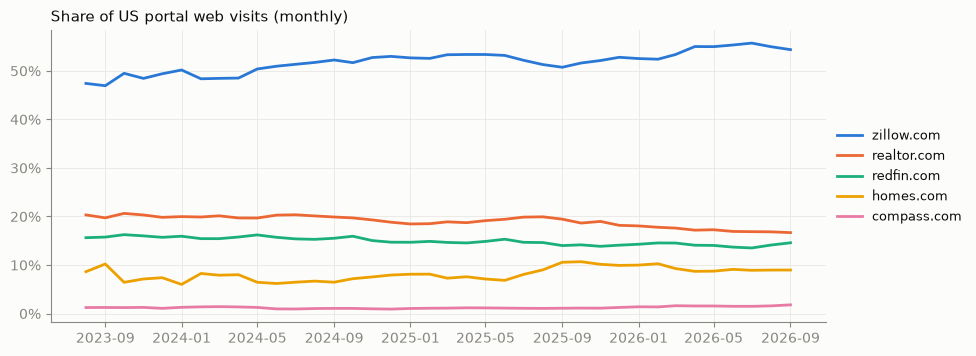

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, d in enumerate(["zillow.com", "realtor.com", "redfin.com", "homes.com", "compass.com"]):
    ax.plot(share.index, share[d], color=C[i], label=d)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Share of US portal web visits (monthly)", loc="left", fontsize=11)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
save(fig, "portal_share"); plt.show()

## 7. zillow.com desktop marketing channels (US)

In [23]:
mc = q("""select date, channel, value from similarweb.common.visits_v2
          where domain = 'zillow.com' and country = 'US' and metric = 'marketing_channels_desktop_visits'
            and date >= '2024-08-01'""")
mc["date"] = pd.to_datetime(mc["date"])
mcm = mc.pivot_table(index=mc.date.dt.to_period("M"), columns="channel", values="value", aggfunc="sum")
mcm = mcm.loc[:"2026-09"]
chan = pd.DataFrame({"share Aug–Sep 26": mcm.loc["2026-08":"2026-09"].sum() / mcm.loc["2026-08":"2026-09"].sum().sum(),
                     "YoY Aug–Sep": mcm.loc["2026-08":"2026-09"].sum() / mcm.loc["2025-08":"2025-09"].sum() - 1})
print("Desktop only. History before 2026-08-18 is a one-off backfill (to 2023-08-15), so treat it as a single vintage.")
chan.sort_values("share Aug–Sep 26", ascending=False).style.format({"share Aug–Sep 26": "{:.1%}", "YoY Aug–Sep": "{:+.1%}"})

Desktop only. History before 2026-08-18 is a one-off backfill (to 2023-08-15), so treat it as a single vintage.


,share Aug–Sep 26,YoY Aug–Sep
channel,,
organic_search,44.0%,+6.9%
direct,31.7%,-0.4%
mail,10.6%,-1.9%
referrals,5.5%,+1.3%
paid_search,3.7%,+5.5%
organic_social,2.7%,+45.0%
paid_social,1.0%,+15.8%
gen_ai,0.4%,+141.3%
display_ads,0.3%,+22.3%


## Findings

1. **Benchmark and signal choice.** Over 14 quarters, web + app combined (Zillow Group web visits + app sessions,
   ratio-scaled) is the only signal that beats consensus on reported **visits**: ≈4.7% MAPE vs 6.7%, with 13 of 14
   beat/miss calls correct. Web-only signals have roughly zero YoY correlation with reported traffic.
   For **MUU**, consensus is tight (≈2% MAPE) and nothing beats it on error. App DAU/MAU is the best
   directional signal (YoY correlation ≈0.5–0.7, about 71% hit rate).
2. **Last 2 months (YoY).**

   | Series | Aug | Sep | Oct month-to-date |
   |---|---|---|---|
   | zillow.com US web visits | +6.7% | +5.9% | +4.1% |
   | Group web visits | +5.7% | +4.7% | +3.4% |
   | Group app sessions | −10.9% | −14.1% | −18% (to Oct 3) |
   | Main-app DAU | −16.0% | −17.5% | −24.4% |

   On a 2-year stack, web is about −4% to −7% and app DAU about −3% to −5%, so the 1-year divergence is mostly about the comparison base.
3. **Q3-26 nowcast.**
   - **Visits:** the web + app signal implies **≈2.29B vs 2.58B consensus (−11%)**, range ≈2.18–2.40B (±1 backtest MAPE).
     Web alone says ≈2.55B (−1%), and an expanding web/app YoY regression says ≈2.36B.
   - **MUU:** app-based signals imply 206–226M against 247M consensus. Web implies ≈251M.
   - Direction: a visits miss is more likely than not. The −11% size is an upper-end read, because the app slump is partly
     category-wide and partly a tough comparison, and app strength in H2-25 was not fully reflected in reported traffic.
4. **Web vs app.**
   - The app decline is gradual, not a step change (the largest weekly YoY move is about 8pp, against a ~30pp slide), and identical on iOS and Android.
   - It is shared with the Realtor.com (−25% to −30%) and Redfin (−17%) apps.
   - Conclusion: this is category-level real-estate app weakness against a tough comparison, with some SensorTower model risk.
     It is not Zillow-specific share loss.
5. **Share.** zillow.com **gained** share of US portal web visits: 55.1% in Apr–Sep 26 vs 52.4% a year ago (+2.7pp).
   Realtor.com lost about 2.5pp, Redfin and Trulia lost about 0.7pp each, Homes.com gained about 0.7pp and Compass about 0.5pp.
   zillow.com desktop channels (Aug–Sep YoY): organic search +7%, direct flat, paid search +6%. Gen-AI referrals are small
   (0.4% share) but up about 2.4x.

**Caveats:**
- SimilarWeb is a single restated vintage.
- SensorTower sessions end 2026-10-03.
- hotpads.com has no web series, and trulia and streeteasy use WW.
- The backtests cover only 14 quarters.